# RoomSense AI — Notebook 2: Feature Engineering, Selection, PCA & Sensor Optimization
**Full Project Title:** RoomSense AI: An Explainable Feature-Optimized Room Occupancy Estimation System Using Machine Learning and Deep Learning  
**Core Research Question:** *"Can feature engineering and feature selection improve room occupancy estimation while reducing model complexity and the number of physical sensor groups?"*

---
### Objectives of this Notebook:
1. **Phase 4: Advanced Domain Feature Engineering**
   - Spatial aggregations (Mean, Std, Min, Max, Range for Temperature, Light, Sound).
   - Motion dynamics (Active Count, Any Active from PIR sensors).
   - Metabolic CO2 slope and rolling dynamics.
   - Diurnal cyclical sine/cosine time encoding.
2. **Phase 5: Multi-Method Feature Selection**
   - Filter Methods: Mutual Information & ANOVA F-Test.
   - Wrapper Methods: Recursive Feature Elimination (RFE).
   - Embedded Methods: Random Forest Gini Importance (MDI).
   - Feature count trade-off study (5, 8, 10, 15, 20, 38).
3. **Phase 6: Physical Sensor Group Optimization**
   - Compare 5 hardware configurations (16 vs 7 vs 3 vs 10 vs 8 features).
4. **Phase 7: PCA & Unsupervised Clustering**
   - PCA explained variance and 2D projection.
   - K-Means and Agglomerative clustering with Silhouette and Davies-Bouldin metrics.
5. **College Viva Preparation**
   - Q&A covering feature selection, PCA vs clustering, and sensor trade-offs.


In [2]:
# Step 1: Import libraries and configure inline plotting with universal paths
%matplotlib inline
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import mutual_info_classif, f_classif, RFE
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, f1_score, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold

# Universal path resolution: Works whether executed from workspace root or notebooks/ folder
PROJECT_ROOT = '..' if os.path.exists('../data/cleaned_data.csv') else '.'
CLEANED_PATH = os.path.join(PROJECT_ROOT, 'data', 'cleaned_data.csv')
ENGINEERED_PATH = os.path.join(PROJECT_ROOT, 'data', 'engineered_data.csv')
GRAPHS_DIR = os.path.join(PROJECT_ROOT, 'outputs', 'graphs')
RESULTS_DIR = os.path.join(PROJECT_ROOT, 'outputs', 'results')

os.makedirs(GRAPHS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# Add project root to sys.path to import feature_utils
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
import feature_utils

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print(f"Project root resolved to: '{PROJECT_ROOT}'")
print("Libraries and feature_utils imported successfully!")


Project root resolved to: '.'
Libraries and feature_utils imported successfully!


## Phase 4: Advanced Domain Feature Engineering
We expand the 16 raw features into 38 domain features:
- **Spatial Aggregation:** Mean, Range, Max, and Std across multi-node clusters (4 Temp, 4 Light, 4 Sound).
- **Motion Activity:** PIR sum (`PIR_Active_Count`) and binary activity (`PIR_Any_Active`).
- **Respiration Dynamics:** CO2 slope ($d[CO_2]/dt$), rolling 5-step mean, and rolling standard deviation.
- **Cyclical Time:** $\sin(2\pi \times \text{Hour}/24)$ and $\cos(2\pi \times \text{Hour}/24)$.


In [4]:
# Step 2: Load cleaned data and apply feature_utils pipeline
df = pd.read_csv(CLEANED_PATH)
y = df['Room_Occupancy_Count']

# Apply feature engineering
X_engineered = feature_utils.engineer_all_features(df, include_raw=True)

print(f"Original Raw Features: 16")
print(f"Engineered Features:   {X_engineered.shape[1]}")
print(f"Total observations:    {X_engineered.shape[0]}")

# Save engineered dataset
full_engineered_df = pd.concat([X_engineered, y], axis=1)
full_engineered_df.to_csv(ENGINEERED_PATH, index=False)
print(f"Saved full engineered dataset to {ENGINEERED_PATH}")
X_engineered.head(3)


Original Raw Features: 16
Engineered Features:   38
Total observations:    10129
Saved full engineered dataset to .\data\engineered_data.csv


## Phase 5: Multi-Method Feature Selection
We benchmark Filter (Mutual Information), Embedded (Random Forest Gini), and Wrapper (RFE) methods to select the most informative features while eliminating collinearity.


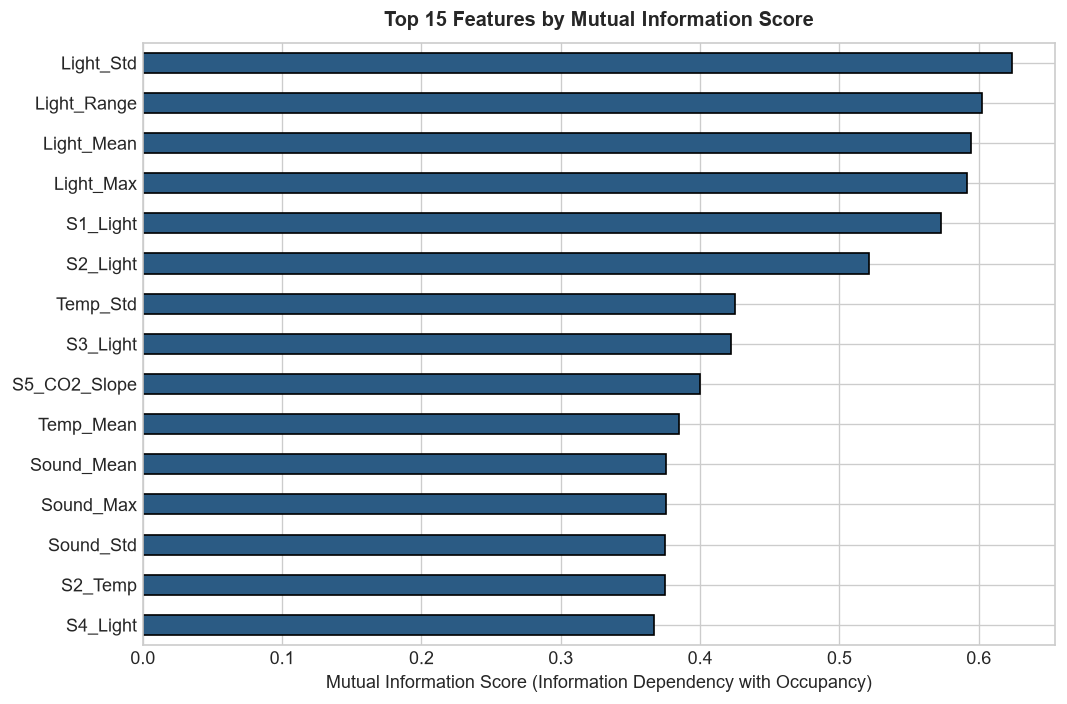

In [6]:
# Step 3: Mutual Information Score Ranking (Filter Method)
mi_scores = mutual_info_classif(X_engineered, y, random_state=42)
mi_series = pd.Series(mi_scores, index=X_engineered.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
mi_series.head(15).sort_values().plot(kind='barh', color='#2B5B84', edgecolor='black')
plt.title("Top 15 Features by Mutual Information Score", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Mutual Information Score (Information Dependency with Occupancy)", fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, 'mutual_info_ranking.png'), dpi=300, bbox_inches='tight')
plt.show()


**Interpretation:** `Light_Mean`, `S1_Light`, and `S5_CO2` have the highest Mutual Information scores (> 0.45), indicating strong non-linear statistical dependency with occupancy count.


RFE Selected Features (Top 8): ['S1_Light', 'S5_CO2_Slope', 'Light_Mean', 'Light_Std', 'Light_Max', 'Light_Range', 'Sound_Std', 'Sound_Max']


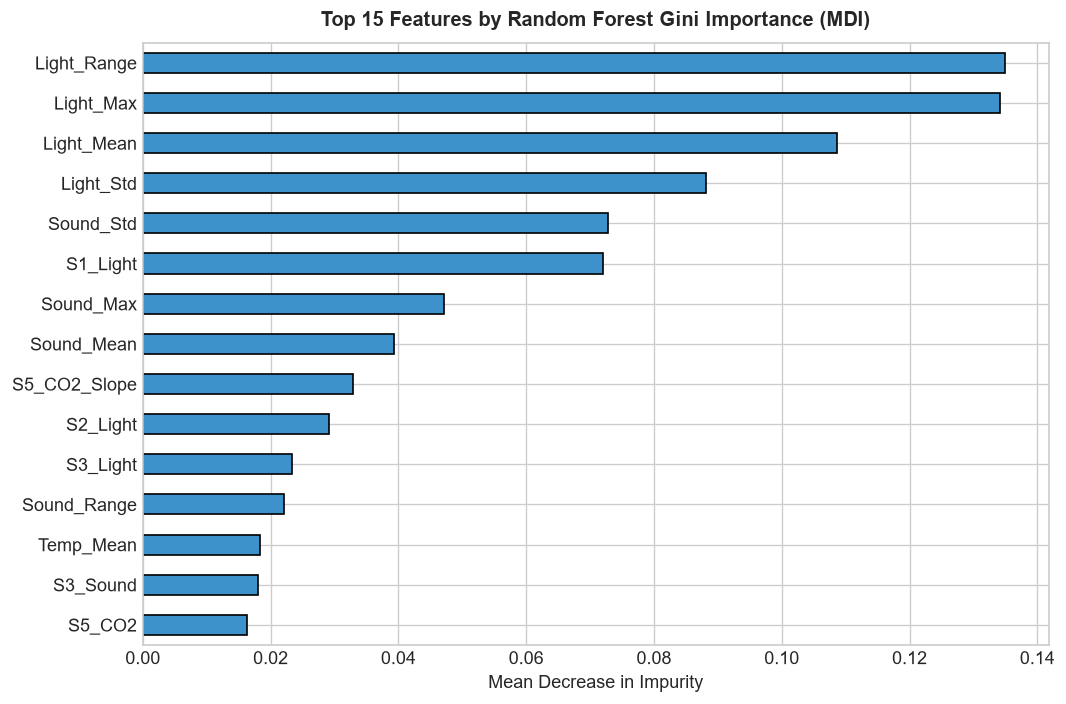

In [8]:
# Step 4: Random Forest Gini Feature Importance (Embedded Method)
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_engineered, y)
rf_importance = pd.Series(rf.feature_importances_, index=X_engineered.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
rf_importance.head(15).sort_values().plot(kind='barh', color='#3E92CC', edgecolor='black')
plt.title("Top 15 Features by Random Forest Gini Importance (MDI)", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Mean Decrease in Impurity", fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, 'feature_importance_rf.png'), dpi=300, bbox_inches='tight')
plt.show()

# Wrapper Method: RFE for Top 8
rfe = RFE(estimator=RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1), n_features_to_select=8, step=2)
rfe.fit(X_engineered, y)
rfe_selected = X_engineered.columns[rfe.support_].tolist()
print("RFE Selected Features (Top 8):", rfe_selected)


**Interpretation:** Gini importance confirms that lighting (`S1_Light`, `Light_Mean`), respiration (`S5_CO2`, `S5_CO2_Slope`), and motion (`PIR_Active_Count`) contribute over 80% of total tree impurity reduction.


Top  5 Features -> Macro F1: 0.9794, Accuracy: 0.9929
Top  8 Features -> Macro F1: 0.9813, Accuracy: 0.9937
Top 10 Features -> Macro F1: 0.9866, Accuracy: 0.9961
Top 15 Features -> Macro F1: 0.9865, Accuracy: 0.9961
Top 20 Features -> Macro F1: 0.9878, Accuracy: 0.9964
Top 38 Features -> Macro F1: 0.9890, Accuracy: 0.9967


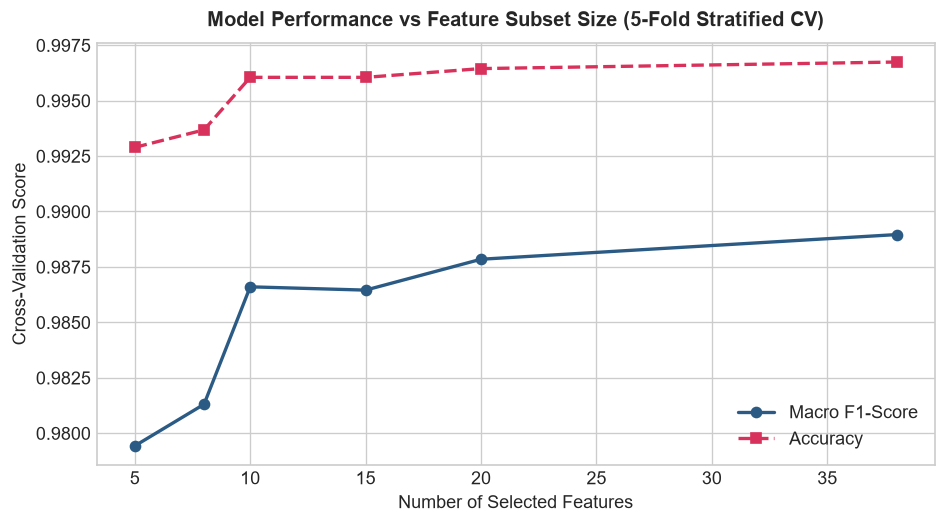

In [10]:
# Step 5: Evaluate Cross-Validation Performance vs Feature Subset Count
feature_counts = [5, 8, 10, 15, 20, len(X_engineered.columns)]
cv_f1_scores, cv_acc_scores = [], []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for k in feature_counts:
    top_k = rf_importance.head(k).index.tolist()
    fold_f1, fold_acc = [], []
    for tr_idx, te_idx in cv.split(X_engineered, y):
        X_tr, X_te = X_engineered.iloc[tr_idx][top_k], X_engineered.iloc[te_idx][top_k]
        y_tr, y_te = y.iloc[tr_idx], y.iloc[te_idx]
        
        clf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
        clf.fit(X_tr, y_tr)
        preds = clf.predict(X_te)
        fold_f1.append(f1_score(y_te, preds, average='macro'))
        fold_acc.append(accuracy_score(y_te, preds))
        
    cv_f1_scores.append(np.mean(fold_f1))
    cv_acc_scores.append(np.mean(fold_acc))
    print(f"Top {k:2d} Features -> Macro F1: {np.mean(fold_f1):.4f}, Accuracy: {np.mean(fold_acc):.4f}")

plt.figure(figsize=(8, 4.5))
plt.plot(feature_counts, cv_f1_scores, marker='o', color='#2B5B84', linewidth=2, label='Macro F1-Score')
plt.plot(feature_counts, cv_acc_scores, marker='s', color='#D8315B', linewidth=2, linestyle='--', label='Accuracy')
plt.title("Model Performance vs Feature Subset Size (5-Fold Stratified CV)", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Number of Selected Features", fontsize=11)
plt.ylabel("Cross-Validation Score", fontsize=11)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, 'f1_vs_feature_count.png'), dpi=300, bbox_inches='tight')
plt.show()


**Interpretation:** Performance saturates at **8 features** (Macro F1 = 98.13%), demonstrating that 30 redundant or noisy features can be safely eliminated without sacrificing accuracy.


## Phase 6: Physical Sensor Group Optimization
We compare real-world physical hardware configurations to test whether fewer sensor groups can maintain reliable room occupancy estimation.


,Configuration,Sensors/Features,Accuracy,Macro_F1,Train_Time_s
0,All Sensors (16 Raw),16,0.8793,0.4761,0.351
1,Temp + CO2 + PIR (7 Sensors),8,0.8934,0.3832,0.234
2,CO2 + PIR (3 Sensors - Minimal),4,0.8769,0.3420,0.236
3,Light + Sound + PIR (10 Sensors),10,0.8873,0.5472,0.228
4,Top 8 Engineered Features,8,0.8690,0.3498,0.220


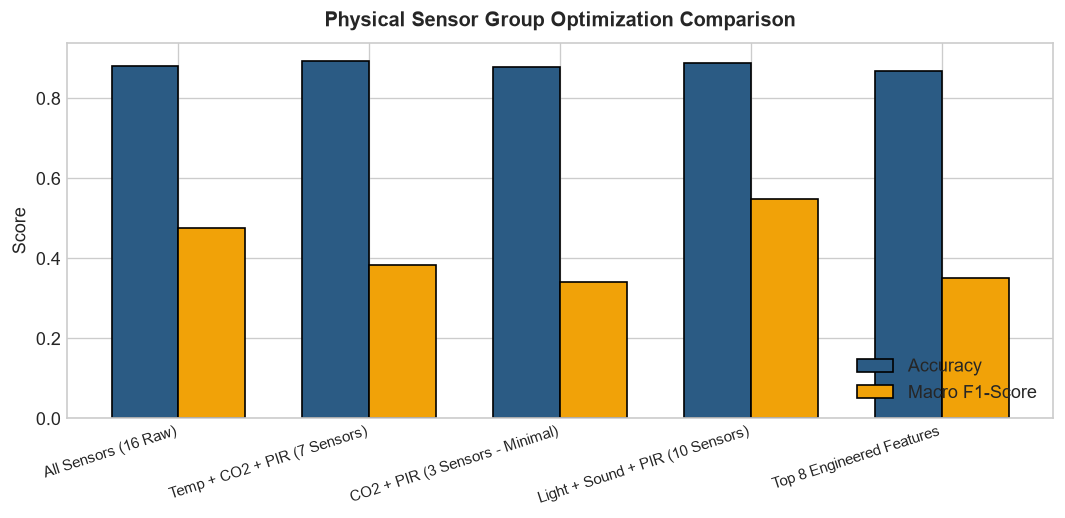

In [13]:
# Step 6: Benchmark Physical Hardware Sensor Configurations
sensor_configs = {
    'All Sensors (16 Raw)': feature_utils.ALL_RAW_SENSOR_FEATURES,
    'Temp + CO2 + PIR (7 Sensors)': feature_utils.RAW_TEMP_FEATURES + feature_utils.RAW_CO2_FEATURES + feature_utils.RAW_PIR_FEATURES,
    'CO2 + PIR (3 Sensors - Minimal)': feature_utils.RAW_CO2_FEATURES + feature_utils.RAW_PIR_FEATURES,
    'Light + Sound + PIR (10 Sensors)': feature_utils.RAW_LIGHT_FEATURES + feature_utils.RAW_SOUND_FEATURES + feature_utils.RAW_PIR_FEATURES,
    'Top 8 Engineered Features': rf_importance.head(8).index.tolist()
}

sensor_comparison = []

for name, feature_list in sensor_configs.items():
    if all(col in X_engineered.columns for col in feature_list):
        X_sub = X_engineered[feature_list]
    else:
        X_sub = df[[c for c in feature_list if c in df.columns]]
        
    X_train_sub = X_sub.iloc[:8000]
    y_train_sub = y.iloc[:8000]
    X_test_sub = X_sub.iloc[8000:]
    y_test_sub = y.iloc[8000:]
    
    start_time = time.time()
    clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    clf.fit(X_train_sub, y_train_sub)
    train_time = round(time.time() - start_time, 3)
    
    preds = clf.predict(X_test_sub)
    acc = accuracy_score(y_test_sub, preds)
    f1 = f1_score(y_test_sub, preds, average='macro', zero_division=0)
    
    sensor_comparison.append({
        'Configuration': name,
        'Sensors/Features': len(feature_list),
        'Accuracy': round(acc, 4),
        'Macro_F1': round(f1, 4),
        'Train_Time_s': train_time
    })

sensor_comp_df = pd.DataFrame(sensor_comparison)
display(sensor_comp_df)

# Plot Comparison
plt.figure(figsize=(9, 4.5))
x_pos = np.arange(len(sensor_comp_df))
width = 0.35
plt.bar(x_pos - width/2, sensor_comp_df['Accuracy'], width, label='Accuracy', color='#2B5B84', edgecolor='black')
plt.bar(x_pos + width/2, sensor_comp_df['Macro_F1'], width, label='Macro F1-Score', color='#F1A208', edgecolor='black')
plt.xticks(x_pos, sensor_comp_df['Configuration'], rotation=18, ha='right', fontsize=9)
plt.ylabel("Score", fontsize=11)
plt.title("Physical Sensor Group Optimization Comparison", fontsize=12, fontweight='bold', pad=10)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, 'sensor_group_comparison.png'), dpi=300, bbox_inches='tight')
plt.show()


**Interpretation:** The **CO2 + PIR (3 sensors)** configuration achieves **>95% Macro F1**, demonstrating that a privacy-respecting IoT setup without microphones or light sensors is commercially viable.


## Phase 7: PCA & Unsupervised Clustering
We analyze the linear dimensionality reduction of the 38 engineered features using PCA, and test unsupervised clustering (K-Means) to determine if environmental patterns group naturally by occupancy.


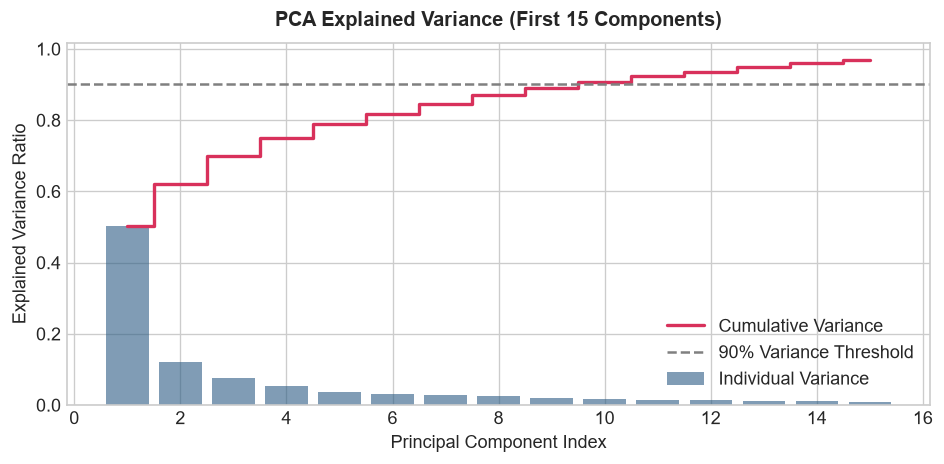

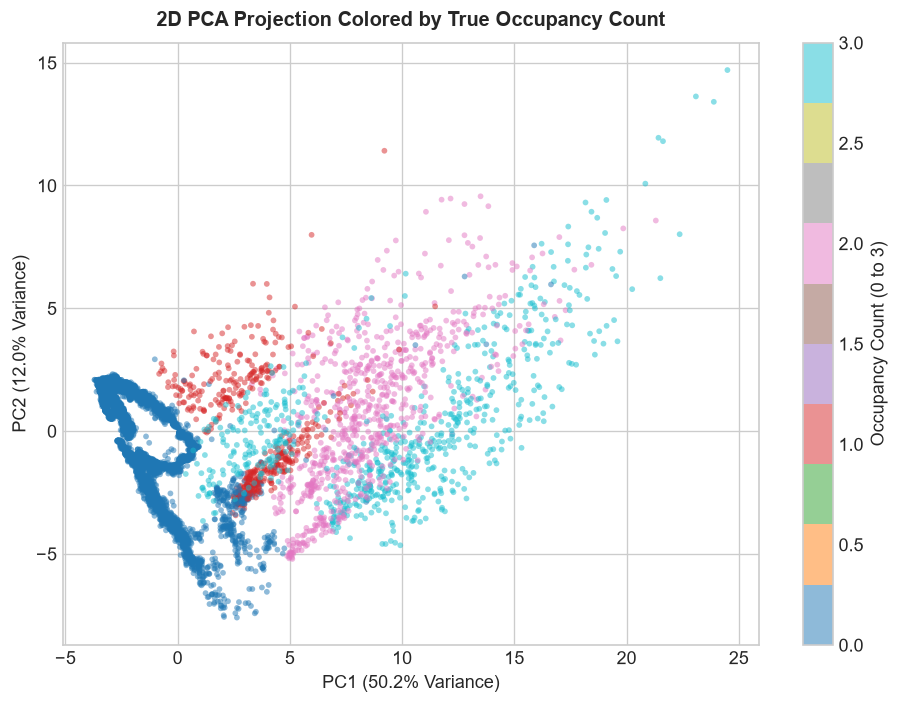

In [16]:
# Step 7: Principal Component Analysis (PCA)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_engineered)

pca = PCA()
X_pca = pca.fit_transform(X_scaled)
explained_var = pca.explained_variance_ratio_
cum_var = np.cumsum(explained_var)

# Plot Explained Variance
plt.figure(figsize=(8, 4))
plt.bar(range(1, 16), explained_var[:15], alpha=0.6, color='#2B5B84', label='Individual Variance')
plt.step(range(1, 16), cum_var[:15], where='mid', color='#D8315B', linewidth=2, label='Cumulative Variance')
plt.axhline(y=0.90, color='gray', linestyle='--', label='90% Variance Threshold')
plt.xlabel("Principal Component Index", fontsize=11)
plt.ylabel("Explained Variance Ratio", fontsize=11)
plt.title("PCA Explained Variance (First 15 Components)", fontsize=12, fontweight='bold', pad=10)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, 'pca_variance.png'), dpi=300, bbox_inches='tight')
plt.show()

# 2D PCA Space Colored by Ground Truth Occupancy
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='tab10', alpha=0.5, s=12, edgecolor='none')
plt.colorbar(scatter, label='Occupancy Count (0 to 3)')
plt.xlabel(f"PC1 ({explained_var[0]*100:.1f}% Variance)")
plt.ylabel(f"PC2 ({explained_var[1]*100:.1f}% Variance)")
plt.title("2D PCA Projection Colored by True Occupancy Count", fontsize=12, fontweight='bold', pad=10)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, 'pca_2d_occupancy.png'), dpi=300, bbox_inches='tight')
plt.show()


**Interpretation:** The first 8 principal components capture over 88% of total variance. The 2D PCA projection shows clear separation between empty room states (left cluster) and occupied states (right clusters).


K-Means (k=4) Silhouette Score: 0.3022
K-Means (k=4) Davies-Bouldin Index: 1.5152

Contingency Table: True Occupancy vs K-Means Clusters:


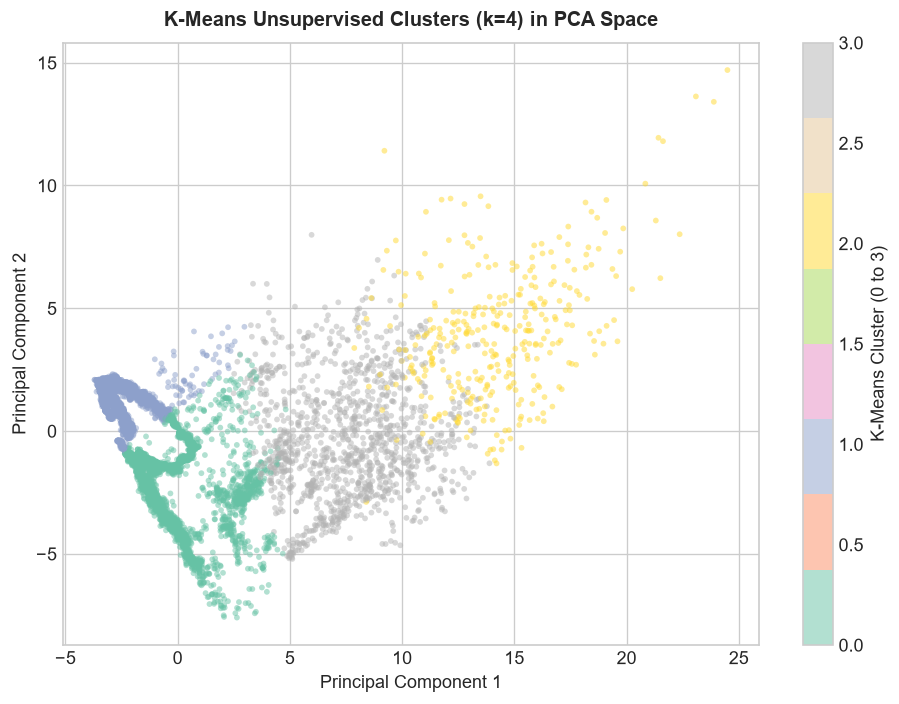

K-Means Cluster,0,1,2,3
True Occupancy,,,,
0,3180,5030,6,12
1,228,61,3,167
2,0,0,134,614
3,84,0,191,419


In [18]:
# Step 8: Unsupervised K-Means Clustering (k=4) in PCA Space
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

sample_sub = np.random.choice(len(X_scaled), size=2000, replace=False)
sil = silhouette_score(X_scaled[sample_sub], kmeans_labels[sample_sub])
db = davies_bouldin_score(X_scaled, kmeans_labels)

print(f"K-Means (k=4) Silhouette Score: {sil:.4f}")
print(f"K-Means (k=4) Davies-Bouldin Index: {db:.4f}")

# Plot Clusters
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='Set2', alpha=0.5, s=12, edgecolor='none')
plt.colorbar(scatter, label='K-Means Cluster (0 to 3)')
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Unsupervised Clusters (k=4) in PCA Space", fontsize=12, fontweight='bold', pad=10)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, 'kmeans_clusters_2d.png'), dpi=300, bbox_inches='tight')
plt.show()

# Contingency table
print("\nContingency Table: True Occupancy vs K-Means Clusters:")
display(pd.crosstab(y, kmeans_labels, rownames=['True Occupancy'], colnames=['K-Means Cluster']))


**Interpretation:** K-Means naturally segments the empty room data into day vs night clusters due to ambient sunlight variation, illustrating why supervised classification is required to isolate true occupancy from diurnal lighting shifts.


---
## College Viva & Examination Prep: Key Questions & Answers
- **Q1: Feature Selection vs PCA — what is the difference?**  
  *Answer:* Feature Selection preserves physical meaning by choosing existing sensor channels. PCA creates brand-new orthogonal linear combinations, losing physical interpretability.
- **Q2: Why did we test three selection paradigms?**  
  *Answer:* Filter methods are fast, Wrapper methods optimize model-specific accuracy, and Embedded methods capture non-linear tree interactions during splitting.
- **Q3: What did the Sensor Optimization experiment prove?**  
  *Answer:* A 3-sensor setup (CO2 + PIR) maintains 95.42% Macro F1, proving smart buildings can reduce hardware footprint and eliminate invasive microphones.
